# Energy
*N-1 contingency: which line trips next*

A power grid has to ride through the loss of any one line. This page takes the IEEE 14-bus test network, takes each of its 20 lines out in turn, solves the AC power flow for every case in one call by Newton's method, one lane per case, with the machines' reactive limits enforced, and flags the lines that end up overloaded. Then it asks how a line's flow moves when the load at one bus moves.

**Time:** ~6 min &middot; **Runs on:** CPU (same code on GPU) &middot;
**You need:** hawk, eagle, NumPy and matplotlib; read first: [hawk in your domain](../vocabulary)

**Colab or Kaggle:** run this first cell (it installs the packages and downloads the helper files this notebook uses). Elsewhere it only checks the imports.

In [1]:
# Colab setup, generated by python -m raptor_docs.nb colab_setup (do not edit).
import os

try:
    import google.colab  # noqa: F401
    HOSTED = True  # a Colab runtime
except ImportError:
    HOSTED = "KAGGLE_KERNEL_RUN_TYPE" in os.environ  # a Kaggle kernel

if HOSTED:
    import importlib.metadata, pathlib, re, shutil, subprocess, sys, urllib.request

    gpu = bool(shutil.which("nvidia-smi")) and subprocess.run(["nvidia-smi", "-L"], capture_output=True).returncode == 0
    extra = ""
    if gpu:
        # the CUDA major the runtime already has: a CuPy that is installed, else torch's, else the driver's
        major = None
        for m in ("13", "12"):
            try:
                importlib.metadata.version(f"cupy-cuda{m}x")
                major = m
                break
            except importlib.metadata.PackageNotFoundError:
                pass
        if major is None:
            try:
                import torch
                major = "13" if str(torch.version.cuda).startswith("13") else None
            except ImportError:
                pass
        if major is None:
            smi = re.search(r"CUDA Version: (\d+)", subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
            major = "13" if smi and int(smi.group(1)) >= 13 else "12"
        extra = f"[cuda{major}]"
        print(f"GPU found: installing the {extra} extras to match this runtime.")
    pre = ["--pre"] if os.environ.get("RAPTOR_PRE") else []  # optional: test a release candidate
    ref = os.environ.get("RAPTOR_REF", "main")  # optional: fetch the helper files from this git ref
    if pre or "RAPTOR_REF" in os.environ:
        print(f"Pre-release test: installing with --pre, helper files from {ref}.")
    # our packages with --upgrade, so a runtime that kept an older release gets the current one
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", *pre, f"raptor-eagle{extra}", f"raptor-hawk{extra}"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matplotlib"])
    base = os.environ.get("RAPTOR_RAW_BASE", "https://raw.githubusercontent.com")  # optional: a local mirror
    top = os.environ.get("RAPTOR_WORKDIR") or ("/kaggle/working" if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "/content")
    root = pathlib.Path(top) / "hawk"
    for rel in (
        "docs/content/_shared/nb_helpers.py",
        "docs/content/_shared/themed_figure.py",
    ):
        (root / rel).parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{base}/amasat01/hawk/{ref}/{rel}", root / rel)
    (root / "docs/content/vocabulary").mkdir(parents=True, exist_ok=True)
    os.chdir(root / "docs/content/vocabulary")
    if not gpu:
        print("Running on the CPU (no GPU in this runtime). For a GPU: " + ("Settings → Accelerator → GPU T4 x2." if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "Runtime → Change runtime type → T4 GPU."))

try:
    import eagle, hawk, matplotlib  # noqa: F401
except ImportError as err:
    raise ImportError(
        "eagle, hawk, matplotlib not found. Install with `pip install matplotlib raptor-eagle raptor-hawk`. For a GPU, add [cuda12] (or [cuda13]) to raptor-eagle and raptor-hawk."
    ) from err

In [2]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "_shared"))
from nb_helpers import gpu_available, on_device, plot_style, show, to_numpy, xp
plot_style()

## The network, once

The IEEE 14-bus case is a classic small test grid (University of Washington power systems archive): 14 buses, 20 lines and transformers, 5 voltage-held machines and 11 loads. It is a steady-state model in per unit on a 100 MVA base; the data is below, so the page is self-contained.

- A **bus** has a voltage, a complex number. Buses 2, 3, 6 and 8 hold their voltage magnitude and give whatever reactive power that takes (bus 2 also delivers 40 MW); bus 1 is the **slack**: it holds voltage and angle and delivers whatever real power the rest needs. The other buses are load buses with fixed real and reactive demand.
- A **line** has a series impedance `r + jx`, a charging susceptance `b` and, for the three transformers, a tap ratio. An outage removes the line's contribution to the network.
- The model leaves out tap and phase control, protection and dynamics. It **does** enforce the machines' reactive limits (Qmin to Qmax in MVAr, in the data below), by the textbook one-way rule: a machine holds its voltage until the solution asks it for more reactive power than its limit; then it becomes a load bus whose reactive output is fixed at that limit, and it is never switched back. The rule is stated in the next section. For networks of real size, reach for a power-system package such as MATPOWER or pandapower.
- **Ratings** are not part of the IEEE data. For the overload flag we assume a rating of 130 % of each line's base-case apparent flow, at least 20 MVA. That is a teaching choice; a utility uses its own limits.

Declare the grid's words as a `KernelKind` once: which line is out, which bus is nudged, and the load level.

In [3]:
import numpy as np
import eagle
import hawk
import hawk.math as m
from hawk import Index, Mutable, Param, Scalar, Vector
from hawk.ext import DATA_ONLY, KernelKind

# IEEE 14-bus test case (University of Washington power systems archive), 100 MVA base. Buses and lines count from 1 here.
# line: from, to, series resistance r, reactance x, total line charging b (per unit), tap ratio on the from side (1 = plain line)
LINES = [
    (1, 2, 0.01938, 0.05917, 0.0528, 1.0), (1, 5, 0.05403, 0.22304, 0.0492, 1.0), (2, 3, 0.04699, 0.19797, 0.0438, 1.0),
    (2, 4, 0.05811, 0.17632, 0.0374, 1.0), (2, 5, 0.05695, 0.17388, 0.0340, 1.0), (3, 4, 0.06701, 0.17103, 0.0346, 1.0),
    (4, 5, 0.01335, 0.04211, 0.0128, 1.0), (4, 7, 0.0, 0.20912, 0.0, 0.978), (4, 9, 0.0, 0.55618, 0.0, 0.969),
    (5, 6, 0.0, 0.25202, 0.0, 0.932), (6, 11, 0.09498, 0.19890, 0.0, 1.0), (6, 12, 0.12291, 0.25581, 0.0, 1.0),
    (6, 13, 0.06615, 0.13027, 0.0, 1.0), (7, 8, 0.0, 0.17615, 0.0, 1.0), (7, 9, 0.0, 0.11001, 0.0, 1.0),
    (9, 10, 0.03181, 0.08450, 0.0, 1.0), (9, 14, 0.12711, 0.27038, 0.0, 1.0), (10, 11, 0.08205, 0.19207, 0.0, 1.0),
    (12, 13, 0.22092, 0.19988, 0.0, 1.0), (13, 14, 0.17093, 0.34802, 0.0, 1.0),
]
#            bus:  1    2     3     4    5    6     7    8    9     10   11   12   13    14
LOAD_MW   = [0.0, 21.7, 94.2, 47.8, 7.6, 11.2, 0.0, 0.0, 29.5, 9.0, 3.5, 6.1, 13.5, 14.9]
LOAD_MVAR = [0.0, 12.7, 19.0, -3.9, 1.6, 7.5, 0.0, 0.0, 16.6, 5.8, 1.8, 1.6, 5.8, 5.0]
GEN_MW    = [0.0, 40.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]       # bus 1 is the slack and finds its own
HELD_V    = [1.06, 1.045, 1.01, None, None, 1.07, None, 1.09, None, None, None, None, None, None]   # voltage-held buses; None = load bus
SHUNT_B   = [0.0] * 8 + [0.19] + [0.0] * 5                                                # capacitor at bus 9 (per unit)
QLIM      = [None, (-40.0, 50.0), (0.0, 40.0), None, None, (-6.0, 24.0), None, (-6.0, 24.0)] + [None] * 6   # machine Qmin, Qmax (MVAr)
BASE_MVA = 100.0
NB, NL = len(LOAD_MW), len(LINES)
GENS = [i for i in range(NB) if QLIM[i]]                    # the machine buses 2, 3, 6, 8 (counted from 0 here)
NG, NB1 = len(GENS), NB - 1
NX = 2 * NB1                                                # unknowns: an angle and a magnitude for every bus but the slack
MAXIT = 60                                                  # Newton iterations a lane may take, switches included
LINE_NAME = [f"{f}-{t}" for f, t, *_ in LINES]


class Network(KernelKind, slug="power_grid"):
    outage: Index       # the line taken out of service (0..19), -1 for none
    kick: Index         # the bus whose injection is nudged (0..13), -1 for none
    nudge: Scalar       # the size of that nudge (MW)
    stress: Scalar      # the load level: 1 is the published load
    omega: Param        # over-relaxation of the DC sweep further down
    tol: Param          # a case has settled when no power or voltage mismatch is above this (per unit)
    guard = DATA_ONLY

Network

__main__.Network

## One lane, one case

Each lane solves its own power flow by **Newton's method** in polar form. The unknowns are the angle and the voltage magnitude of every bus but the slack: 26 numbers. Each iteration builds the 26 x 26 Jacobian of the power mismatches, entry by entry, with `m.mat`, and solves it with `m.solve`. The Jacobian is never in registers whole, and the matrix is a hawk value like any other, so `jvp` differentiates through it.

A machine bus holds its voltage: its magnitude equation is replaced by `V - V_set = 0`, which is the identity row in the Jacobian. A load bus balances reactive power instead. The reactive limits follow the textbook **one-way PV to PQ switching** rule (the one MATPOWER's `enforce_q_lims` applies):

1. Solve with every machine holding its voltage, until the mismatch is below `tol`.
2. Read each machine's reactive output. A machine that is outside `Qmin` to `Qmax` becomes a load bus whose reactive output is fixed at the limit it broke. All such machines switch together.
3. Solve again from where you are, and repeat from step 2.
4. A machine that has switched stays a load bus. It is never switched back, so the sequence of machine sets only shrinks and cannot chatter.

A lane that is not within `tol` after 60 iterations, or whose solve fails, is reported as not converged. The network is fixed data, so the bus and line loops are plain Python helpers that run once, when the kernel is traced, and unroll into straight-line code. What differs between lanes is the outage: `line_switches` turns the lane's line off, and the admittances follow. The whole rule is one loop: each iteration either takes a Newton step or applies a switch, and **each lane stops on its own**: `if done > 0.5: break` is the first statement of the loop. After the mismatch first falls below `tol` the lane takes one more step, so that a derivative through the loop has settled too.

The line that islands bus 8 (7-8) is handled in the helper: a bus with no line attached keeps its voltage, and its two rows of the Jacobian become identity rows. That test is "no line at all", not connectivity, which is enough for N-1 on this case, where only bus 8 can island.

In [4]:
class Cx:
    """A complex number as two traced reals. Plain Python: it runs once, when the kernel is traced."""
    def __init__(self, re, im=0.0): self.re, self.im = re, im
    def __add__(self, o): o = o if isinstance(o, Cx) else Cx(o); return Cx(self.re + o.re, self.im + o.im)
    def __sub__(self, o): o = o if isinstance(o, Cx) else Cx(o); return Cx(self.re - o.re, self.im - o.im)
    def __mul__(self, o):
        if not isinstance(o, Cx): return Cx(self.re * o, self.im * o)
        return Cx(self.re * o.re - self.im * o.im, self.re * o.im + self.im * o.re)
    def conj(self): return Cx(self.re, -self.im)
    def abs2(self): return self.re * self.re + self.im * self.im


def line_switches(outage):
    return [m.where(outage == k, 0.0, 1.0) for k in range(NL)]             # 1 = in service, 0 = this lane's outage


def admittances(on):
    # the bus admittance matrix, kept as its diagonal and one (from, to, ...) record per line; an outaged line contributes zero
    ydiag = [Cx(0.0, SHUNT_B[i]) for i in range(NB)]
    ends = []
    for k, (f, t, r, x, b, a) in enumerate(LINES):
        f, t = f - 1, t - 1
        y = 1.0 / complex(r, x)
        ff, tt, ft = (y + 0.5j * b) / a**2, y + 0.5j * b, -y / a
        ff, tt, ft = (Cx(c.real * on[k], c.imag * on[k]) for c in (ff, tt, ft))
        ydiag[f] = ydiag[f] + ff
        ydiag[t] = ydiag[t] + tt
        ends.append((f, t, ff, tt, ft))
    return ydiag, ends


def live_buses(ydiag):
    return [m.where(ydiag[i].abs2() > 1e-9, 1.0, 0.0) for i in range(NB)]    # a bus cut off from every line stays where it is


def flat_start(stress):
    # angles, magnitudes, the machines that still hold (all), their reactive set points once switched, and the mismatch record
    return (m.vec(*[0.0] * NB), m.vec(*[v or 1.0 for v in HELD_V]), m.vec(*[1.0] * NG),
            m.vec(*[-stress * LOAD_MVAR[g] / BASE_MVA for g in GENS]), m.vec(*[0.0] * 8))


def injections(th, vm, ydiag, ends):
    # the real and reactive power each bus injects into the network, from the polar voltages
    P = [ydiag[i].re * vm[i] * vm[i] for i in range(NB)]
    Q = [-ydiag[i].im * vm[i] * vm[i] for i in range(NB)]
    for f, t, ff, tt, ft in ends:
        c, s, vv = m.cos(th[f] - th[t]), m.sin(th[f] - th[t]), vm[f] * vm[t]
        P[f] = P[f] + vv * (ft.re * c + ft.im * s)
        Q[f] = Q[f] + vv * (ft.re * s - ft.im * c)
        P[t] = P[t] + vv * (ft.re * c - ft.im * s)
        Q[t] = Q[t] - vv * (ft.re * s + ft.im * c)
    return P, Q


def specified_power(kick, nudge, stress):
    p = [(GEN_MW[i] - stress * LOAD_MW[i] + m.where(kick == i, nudge, 0.0)) / BASE_MVA for i in range(NB)]
    q = [-stress * LOAD_MVAR[i] / BASE_MVA for i in range(NB)]
    return p, q


def mismatch(vm, P, Q, p_set, q_spec, q_set, pv, live):
    # the 26 equations: real power at every bus but the slack, then reactive power at the load buses and the switched machines,
    # or the held magnitude at a machine that still holds its voltage. A bus with no line gets the equation "do not move"
    f = [live[i] * (P[i] - p_set[i]) for i in range(1, NB)]
    held = {g: k for k, g in enumerate(GENS)}
    for i in range(1, NB):
        if i in held:
            k = held[i]
            f.append(live[i] * (pv[k] * (vm[i] - HELD_V[i]) + (1.0 - pv[k]) * (Q[i] - q_set[k])))
        else:
            f.append(live[i] * (Q[i] - q_spec[i]))
    return f


def jacobian(th, vm, ydiag, ends, P, Q, pv, live):
    # d(mismatch) / d(angles, magnitudes): the polar Newton Jacobian, written entry by entry
    J = [[0.0] * NX for _ in range(NX)]

    def add(r, c, v):
        J[r][c] = J[r][c] + v

    for i in range(1, NB):
        ri, qi = i - 1, NB1 + i - 1
        add(ri, ri, -Q[i] - ydiag[i].im * vm[i] * vm[i])
        add(ri, qi, P[i] / vm[i] + ydiag[i].re * vm[i])
        add(qi, ri, P[i] - ydiag[i].re * vm[i] * vm[i])
        add(qi, qi, Q[i] / vm[i] - ydiag[i].im * vm[i])
    for f, t, ff, tt, ft in ends:
        for i, j in ((f, t), (t, f)):
            if i == 0 or j == 0:                                           # the slack's angle and magnitude are fixed
                continue
            c, s, G, B = m.cos(th[i] - th[j]), m.sin(th[i] - th[j]), ft.re, ft.im
            ri, rj, qi, qj = i - 1, j - 1, NB1 + i - 1, NB1 + j - 1
            add(ri, rj, vm[i] * vm[j] * (G * s - B * c))
            add(ri, qj, vm[i] * (G * c + B * s))
            add(qi, rj, -vm[i] * vm[j] * (G * c + B * s))
            add(qi, qj, vm[i] * (G * s - B * c))
    held = {g: k for k, g in enumerate(GENS)}
    for i in range(1, NB):
        ri, qi = i - 1, NB1 + i - 1
        keep_q = live[i] * (1.0 - pv[held[i]]) if i in held else live[i]   # a machine holding its voltage has no reactive row
        for c in range(NX):
            J[ri][c] = J[ri][c] * live[i]
            J[qi][c] = J[qi][c] * keep_q
        J[ri][ri] = J[ri][ri] + (1.0 - live[i])
        J[qi][qi] = J[qi][qi] + (1.0 - keep_q)
    return m.mat(J)


def newton_step(th, vm, pv, q_set, ydiag, ends, live, kick, nudge, stress, tol):
    # one iteration of the whole rule: a Newton step, or a switch of the machines that broke a limit
    p_spec, q_spec = specified_power(kick, nudge, stress)
    P, Q = injections(th, vm, ydiag, ends)
    f = mismatch(vm, P, Q, p_spec, q_spec, q_set, pv, live)
    worst = 0.0
    for v in f:
        worst = m.where(m.abs(v) > worst, m.abs(v), worst)
    close = m.where(worst < tol, 1.0, 0.0)
    switched, q_new = [], []
    for k, g in enumerate(GENS):
        lo, hi = QLIM[g]
        q_gen = Q[g] * BASE_MVA + stress * LOAD_MVAR[g]                    # the machine's reactive output, MVAr
        above, below = m.where(q_gen > hi + 1e-6, 1.0, 0.0), m.where(q_gen < lo - 1e-6, 1.0, 0.0)
        switched.append(close * pv[k] * live[g] * m.where(above + below > 0.5, 1.0, 0.0))     # only a converged machine that still holds
        limit = m.where(above > 0.5, hi, lo)
        q_new.append(m.where(switched[k] > 0.5, (limit - stress * LOAD_MVAR[g]) / BASE_MVA, q_set[k]))
    any_switch = 0.0
    for s in switched:
        any_switch = m.where(s > any_switch, s, any_switch)
    step = 1.0 - any_switch                                                 # a switch changes the equations: no step this time
    dx, _ = m.solve(jacobian(th, vm, ydiag, ends, P, Q, pv, live), m.vec(*[-v for v in f]))
    th_new = m.vec(*[th[i] + (step * dx[i - 1] if i > 0 else 0.0) for i in range(NB)])
    vm_new = m.vec(*[vm[i] + (step * dx[NB1 + i - 1] if i > 0 else 0.0) for i in range(NB)])
    pv_new = m.vec(*[pv[k] * (1.0 - switched[k]) for k in range(NG)])
    return th_new, vm_new, pv_new, m.vec(*q_new), close * (1.0 - any_switch), worst


def record(trace, n, worst):
    return m.vec(*[m.where(m.abs(n - (j + 1.0)) < 0.5, worst, trace[j]) for j in range(8)])


def rectangular(th, vm):
    return m.vec(*[vm[i] * m.cos(th[i]) for i in range(NB)]), m.vec(*[vm[i] * m.sin(th[i]) for i in range(NB)])


def machine_q(th, vm, ydiag, ends, stress):
    P, Q = injections(th, vm, ydiag, ends)
    return m.vec(*[Q[g] * BASE_MVA + stress * LOAD_MVAR[g] for g in GENS])


def line_flows(vr, vi, ends):
    # real power at the from end and the larger apparent power of the two ends, per line, in MW and MVA; the slack's output
    V = [Cx(vr[i], vi[i]) for i in range(NB)]
    pf, sf, slack = [], [], 0.0
    for f, t, ff, tt, ft in ends:
        s_from = V[f] * (ff * V[f] + ft * V[t]).conj()
        s_to = V[t] * (tt * V[t] + ft * V[f]).conj()
        pf.append(s_from.re * BASE_MVA)
        sf.append(m.sqrt(m.where(s_from.abs2() > s_to.abs2(), s_from.abs2(), s_to.abs2())) * BASE_MVA)
        if f == 0: slack = slack + s_from.re * BASE_MVA
        if t == 0: slack = slack + s_to.re * BASE_MVA
    return m.vec(*pf), m.vec(*sf), slack


"helpers ready"

'helpers ready'

In [5]:
@Network
def power_flow(outage, kick, nudge, stress, omega, tol,
               vre: Mutable[Vector[NB]], vim: Mutable[Vector[NB]], pf: Mutable[Vector[NL]], sf: Mutable[Vector[NL]],
               p_slack: Mutable[Scalar], iterations: Mutable[Scalar], settled: Mutable[Scalar],
               q_machine: Mutable[Vector[NG]], holding: Mutable[Vector[NG]], trace: Mutable[Vector[8]]):
    ydiag, ends = admittances(line_switches(outage))
    live = live_buses(ydiag)
    th, vm, pv, q_set, seen = flat_start(stress)                         # pv: 1 = this machine still holds its voltage
    done = 0.0
    n = 0.0
    for _ in range(MAXIT):
        if done > 0.5:
            break
        n = n + 1.0
        th, vm, pv, q_set, done, worst = newton_step(th, vm, pv, q_set, ydiag, ends, live, kick, nudge, stress, tol)
        seen = record(seen, n, worst)
    vr, vi = rectangular(th, vm)
    vre = vr
    vim = vi
    pf, sf, p_slack = line_flows(vr, vi, ends)
    q_machine = machine_q(th, vm, ydiag, ends, stress)
    holding = pv
    trace = seen
    iterations = n
    settled = done


power_flow

<Kernel power_flow slots=15>

## Every outage, one call

`cases` runs from `-1` (no outage: the base case) to line 19. That is 21 independent lanes. `eagle.deploy(power_flow).run(...)` takes the planes by name and returns the outputs by name; vector outputs come back as `(entries, lanes)`. A lane that does not converge is not a result: the page counts those as **insecure**, because a grid state with no solution is the worst answer a contingency study can give.

In [6]:
OMEGA, TOL = 1.6, 1e-12
cases = np.arange(-1, NL, dtype=np.int32)                                 # -1 is the base case, then each line out in turn
NS = len(cases)
grid = eagle.deploy(power_flow)


def run_cases(outage, kick=None, nudge=None, stress=None, tol=TOL):
    n = len(outage)
    zeros = np.zeros(n)
    got = grid.run(outage=outage, kick=np.full(n, -1, np.int32) if kick is None else kick, nudge=zeros if nudge is None else nudge,
                   stress=np.ones(n) if stress is None else stress, omega=OMEGA, tol=tol)
    return {k: np.asarray(v) for k, v in got.items()}


out = run_cases(cases)
insecure = out["settled"] < 0.5
print(f"{insecure.sum()} of {NS} cases did not converge: insecure" + (f" ({[LINE_NAME[c] if c >= 0 else 'base' for c in cases[insecure]]})" if insecure.any() else ""))
ok = ~insecure                                              # the cases with a power flow; the others have no answer to report
volt = out["vre"].T + 1j * out["vim"].T                    # (case, bus): planes come back as (entries, lanes)
iters, load_pu = out["iterations"], np.where(ok[:, None], out["sf"].T, np.nan)       # load_pu: apparent power (MVA) per case and line
switched = (out["holding"].T < 0.5) & ok[:, None]          # (case, machine): a machine that hit a limit and became a load bus
degree = np.zeros((NS, NB))                                 # lines in service at each bus, per case
for j, k in enumerate(cases):
    for kk, (f, t, *_rest) in enumerate(LINES):
        if kk != k:
            degree[j, f - 1] += 1; degree[j, t - 1] += 1
volt = np.where((degree > 0) & ok[:, None], volt, np.nan)   # a bus with no line left is de-energised: not a voltage
print(f"{ok.sum()} cases converged in {iters[ok].min():.0f} to {iters[ok].max():.0f} iterations (base case {iters[0]:.0f}); {switched.any(axis=1).sum()} of them switched at least one machine to a load bus")

1 of 21 cases did not converge: insecure (['1-2'])
20 cases converged in 5 to 10 iterations (base case 5); 4 of them switched at least one machine to a load bus


## Check it against what is published, and against another solver

Four checks.

- **The published solution.** The base case must match the standard IEEE 14-bus result: voltage magnitudes and angles, and the slack's output of 232.4 MW. The magnitudes are published to three decimals, so their tolerance is that rounding (5e-4). The angles are published to two decimals of a degree but are not all within that rounding of the exact solution (the archive's own solve stopped early), so the angle tolerance is 0.01 degrees, the accuracy of the published solution, not its rounding.
- **Another solver.** Newton's method in NumPy, with the Jacobian by forward differences and the same one-way switching rule, run on all 21 cases and compared **per outage**; where the kernel finds no solution the reference must fail too. It shares neither the Jacobian nor the loop with the kernel, so agreement is a real test of the answer. Both switch every machine that broke a limit at once, so the sequences of machine sets are the same.
- **Power balance and limits.** From the returned voltages, rebuild the bus admittance matrix in NumPy and check that each bus injects what the data says: real power at every bus but the slack, reactive power at the load buses and at the switched machines. A machine still holding its voltage is at its set magnitude and inside its limits; a switched machine's reactive output equals the limit it broke.
- **Quadratic convergence.** Newton's method squares the error each iteration once it is close. The kernel records the largest mismatch of its first eight iterations; the base case shows it.

In [7]:
PUBLISHED_V = [1.060, 1.045, 1.010, 1.019, 1.020, 1.070, 1.062, 1.090, 1.056, 1.051, 1.057, 1.055, 1.050, 1.036]
PUBLISHED_ANGLE = [0.0, -4.98, -12.72, -10.33, -8.78, -14.22, -13.37, -13.36, -14.94, -15.10, -14.79, -15.07, -15.16, -16.04]   # degrees
PUBLISHED_SLACK_MW = 232.4

dv = np.abs(np.abs(volt[0]) - PUBLISHED_V).max()
da = np.abs(np.degrees(np.angle(volt[0])) - PUBLISHED_ANGLE).max()
dp = abs(out["p_slack"][0] - PUBLISHED_SLACK_MW)
assert dv < 5e-4 and da < 0.01 and dp < 0.05, (dv, da, dp)
print(f"base case against the published solution: voltage magnitudes within {dv:.1e} pu, angles within {da:.3f} deg, slack output {out['p_slack'][0]:.2f} MW (published {PUBLISHED_SLACK_MW})")


def ybus_np(outaged):
    Y = np.diag(1j * np.array(SHUNT_B))
    for k, (f, t, r, x, b, a) in enumerate(LINES):
        if k == outaged:
            continue
        f, t, y = f - 1, t - 1, 1 / complex(r, x)
        Y[f, f] += (y + 0.5j * b) / a**2; Y[t, t] += y + 0.5j * b; Y[f, t] -= y / a; Y[t, f] -= y / a
    return Y


def newton(outaged, stress=1.0, inject=None, max_iter=MAXIT, start=None):
    # Newton's method in NumPy with the same one-way PV -> PQ rule: unknowns are the angles of all live buses but the slack and the
    # magnitudes of the live load buses and switched machines; the Jacobian is by forward differences. `start` = (voltages, {machine: limit}) warm-starts from an earlier solution and keeps its switched machines. `inject` = (bus, MW) adds an
    # injection at a bus (the slack makes it up). Returns the voltages, the iteration count, whether it converged and the switched machines
    Y = ybus_np(outaged)
    live = np.abs(np.diag(Y)) > 1e-9
    held = np.array([v is not None for v in HELD_V])
    ang = [i for i in range(1, NB) if live[i]]
    p_set = (np.array(GEN_MW) - stress * np.array(LOAD_MW)) / BASE_MVA
    if inject is not None:
        p_set[inject[0]] += inject[1] / BASE_MVA
    q_set = -stress * np.array(LOAD_MVAR) / BASE_MVA
    th, vm = np.zeros(NB), np.array([v or 1.0 for v in HELD_V])
    gone, limits = set(), {}                                  # machines that have become load buses, and the limit each sits at
    if start is not None:
        th, vm = np.angle(start[0]), np.abs(start[0])
        for g, lim in start[1].items():
            gone.add(g); limits[g] = lim; q_set[g] = (lim - stress * LOAD_MVAR[g]) / BASE_MVA
    used = 0
    while True:
        mag = [i for i in range(1, NB) if live[i] and (not held[i] or i in gone)]

        def mismatch(th, vm):
            V = vm * np.exp(1j * th)
            S = V * np.conj(Y @ V)
            return np.r_[(S.real - p_set)[ang], (S.imag - q_set)[mag]]

        converged = False
        while used < max_iter:
            f0 = mismatch(th, vm)
            if not np.all(np.isfinite(f0)):
                return np.full(NB, np.nan, dtype=complex), used, False, gone, limits
            if np.abs(f0).max() < 1e-12:
                converged = True
                break
            J = np.empty((len(f0), len(f0)))
            for c in range(len(f0)):                          # the Jacobian column by column, by forward differences
                th2, vm2 = th.copy(), vm.copy()
                if c < len(ang): th2[ang[c]] += 1e-7
                else: vm2[mag[c - len(ang)]] += 1e-7
                J[:, c] = (mismatch(th2, vm2) - f0) / 1e-7
            try:
                d = np.linalg.solve(J, -f0)
            except np.linalg.LinAlgError:
                return np.full(NB, np.nan, dtype=complex), used, False, gone, limits
            th[ang] += d[:len(ang)]; vm[mag] += d[len(ang):]
            used += 1
        if not converged:
            return np.full(NB, np.nan, dtype=complex), used, False, gone, limits
        V = vm * np.exp(1j * th)
        q_gen = (V * np.conj(Y @ V)).imag * BASE_MVA + stress * np.array(LOAD_MVAR)
        broke = [g for g in GENS if live[g] and g not in gone and not (QLIM[g][0] - 1e-6 <= q_gen[g] <= QLIM[g][1] + 1e-6)]
        if not broke:
            return V, used, True, gone, limits
        for g in broke:                                       # every machine that broke a limit switches, at that limit
            gone.add(g)
            limits[g] = QLIM[g][1] if q_gen[g] > QLIM[g][1] else QLIM[g][0]
            q_set[g] = ((QLIM[g][1] if q_gen[g] > QLIM[g][1] else QLIM[g][0]) - stress * LOAD_MVAR[g]) / BASE_MVA


def flows_np(V, outaged):
    # real power at the from end of every line, MW
    res = []
    for k, (f, t, r, x, b, a) in enumerate(LINES):
        if k == outaged:
            res.append(0.0); continue
        y = 1 / complex(r, x)
        ff, ft = (y + 0.5j * b) / a**2, -y / a
        res.append((V[f - 1] * np.conj(ff * V[f - 1] + ft * V[t - 1])).real * BASE_MVA)
    return np.array(res)


solved = [newton(None if k < 0 else k) for k in cases]
reference = np.array([s[0] for s in solved])
assert [s[2] for s in solved] == list(ok), "the reference converges in the same cases"
reference = np.where(np.isnan(volt), np.nan, reference)      # a de-energised bus is not compared
per_outage = np.nanmax(np.abs(volt[ok] - reference[ok]), axis=1)
TOL_NEWTON = 1e-8
assert per_outage.max() < TOL_NEWTON, per_outage
same_set = [set(np.flatnonzero(switched[j])) == {GENS.index(g) for g in solved[j][3]} for j in np.flatnonzero(ok)]
assert all(same_set), "the same machines switched"
print(f"all {ok.sum()} converged cases against Newton's method in NumPy, per outage, and both fail on the same {(~ok).sum()}: worst voltage gap {per_outage.max():.1e} pu < {TOL_NEWTON:g}, and the same machines switched in every case")

worst_p = worst_q = 0.0
for j, k in enumerate(cases):                              # does the answer close the books at every bus?
    if not ok[j]:
        continue
    Vj = np.where(np.isnan(volt[j]), 1.0, volt[j])
    Yj = ybus_np(None if k < 0 else k)
    S = Vj * np.conj(Yj @ Vj)
    live = np.abs(np.diag(Yj)) > 1e-9
    p_set = (np.array(GEN_MW) - np.array(LOAD_MW)) / BASE_MVA
    worst_p = max(worst_p, np.abs((S.real - p_set)[1:][live[1:]]).max())
    for i in range(1, NB):
        if not live[i]:
            continue
        if i in GENS:
            g = GENS.index(i)
            q_gen = S[i].imag * BASE_MVA + LOAD_MVAR[i]
            assert abs(q_gen - out["q_machine"][g, j]) < 1e-6
            lo, hi = QLIM[i]
            if switched[j, g]:                              # a switched machine sits at the limit it broke
                worst_q = max(worst_q, min(abs(q_gen - lo), abs(q_gen - hi)) / BASE_MVA)
            else:                                           # a holding machine: at its magnitude, inside its limits
                assert abs(abs(Vj[i]) - HELD_V[i]) < 1e-9 and lo - 1e-6 <= q_gen <= hi + 1e-6, (j, i, q_gen)
        else:
            worst_q = max(worst_q, abs(S[i].imag + LOAD_MVAR[i] / BASE_MVA))
    assert abs(S[0].real * BASE_MVA - out["p_slack"][j]) < 1e-6
TOL_BALANCE = 1e-9
assert worst_p < TOL_BALANCE and worst_q < TOL_BALANCE, (worst_p, worst_q)
print(f"power balance at every bus, every case: worst real mismatch {worst_p:.1e} pu, reactive {worst_q:.1e} pu < {TOL_BALANCE:g}; switched machines sit at their limits")
loss = out["p_slack"][0] + sum(GEN_MW) - sum(LOAD_MW)
print(f"base case: generation {out['p_slack'][0] + sum(GEN_MW):.2f} MW = load {sum(LOAD_MW):.2f} MW + losses {loss:.2f} MW")

base case against the published solution: voltage magnitudes within 4.4e-04 pu, angles within 0.008 deg, slack output 232.39 MW (published 232.4)
all 20 converged cases against Newton's method in NumPy, per outage, and both fail on the same 1: worst voltage gap 4.1e-14 pu < 1e-08, and the same machines switched in every case
power balance at every bus, every case: worst real mismatch 6.2e-15 pu, reactive 1.7e-14 pu < 1e-09; switched machines sit at their limits
base case: generation 272.39 MW = load 259.00 MW + losses 13.39 MW


In [8]:
residual = out["trace"][:, 0]                                  # the largest mismatch of each of the first eight iterations, base case, per unit
used = min(int(iters[0]), 8)
print("base case, largest mismatch by iteration:", " ".join(f"{r:.1e}" for r in residual[:used]))
ratios = [residual[k + 1] / residual[k] ** 2 for k in range(used - 2) if residual[k] < 1e-2 and residual[k + 1] > 1e-14]
assert ratios and max(ratios) < 200, ratios
print(f"each mismatch is about the square of the one before (ratio r[k+1] / r[k]^2 at most {max(ratios):.1f}): quadratic convergence")

base case, largest mismatch by iteration: 9.2e-01 1.0e-01 7.2e-04 6.1e-08 6.6e-15
each mismatch is about the square of the one before (ratio r[k+1] / r[k]^2 at most 0.1): quadratic convergence


## Push the load until the grid has no solution

Raise the load level on every case, 1.0 to 1.9 times the published load. At some point there is no power flow at all: the loads ask for more than the network can deliver at any voltage. Newton's method then does not converge, the lane stops at 60 iterations, and the case is **insecure**. The count grows from the one outage that is already insecure at the published load to every case at the highest level. The NumPy reference follows the same rule, so the two must agree on which lanes converge, and on the answer where they do.

In [9]:
LEVELS = [1.0, 1.3, 1.6, 1.9]
lane_out, lane_stress = np.tile(cases, len(LEVELS)), np.repeat(LEVELS, NS)
stressed = run_cases(lane_out, stress=lane_stress)
lane_ok = stressed["settled"] > 0.5
ref = [newton(None if k < 0 else k, stress=s) for k, s in zip(lane_out, lane_stress)]
ref_ok = np.array([r[2] for r in ref])
assert (lane_ok == ref_ok).all(), "the kernel and the reference agree on which lanes converge"
v_all = stressed["vre"].T + 1j * stressed["vim"].T
gap_ok = max(np.nanmax(np.abs(v_all[j] - ref[j][0])) for j in np.flatnonzero(lane_ok))
assert gap_ok < 1e-7, gap_ok
for level in LEVELS:
    here = lane_stress == level
    print(f"load x{level:.1f}: {int((~lane_ok[here]).sum())} of {NS} cases insecure (no converged power flow)")
print(f"{int((~lane_ok).sum())} of {len(lane_ok)} lanes did not converge, the same lanes as the reference; the {int(lane_ok.sum())} that did agree with it to {gap_ok:.1e} pu")

load x1.0: 1 of 21 cases insecure (no converged power flow)
load x1.3: 1 of 21 cases insecure (no converged power flow)
load x1.6: 7 of 21 cases insecure (no converged power flow)
load x1.9: 21 of 21 cases insecure (no converged power flow)
30 of 84 lanes did not converge, the same lanes as the reference; the 54 that did agree with it to 5.6e-12 pu


## Which outages overload a line

Loading is a line's apparent power over its rating, taken at the heavier of its two ends. The table lists the five outages that overload the most lines, the lines that go over, and the machines that hit a reactive limit and became load buses. The voltages and flows already include that: the limits are enforced, not just reported.

In [10]:
RATING = np.maximum(1.3 * load_pu[0], 20.0)                 # MVA: 130 % of the base-case flow, at least 20 MVA (an assumption, see above)
loading = load_pu / RATING                                  # (case, line)
overloaded = [np.flatnonzero(loading[j] > 1.0) for j in range(NS)]
assert (loading[0] < 1.0).all() and loading[0].max() < 0.78
assert not switched[0].any(), "the base case is within every limit"
order_of_harm = np.argsort([-len(o) for o in overloaded[1:]], kind="stable")[:5] + 1
assert ok[order_of_harm].all()
at_limit = lambda j: ", ".join(f"bus {GENS[g] + 1} ({out['q_machine'][g, j]:.0f} MVAr)" for g in np.flatnonzero(switched[j]))
print("line out  iterations  overloaded lines                    worst loading  machines now at a reactive limit")
for j in order_of_harm:
    names = ", ".join(LINE_NAME[i] for i in overloaded[j])
    print(f"{LINE_NAME[cases[j]]:>8}  {iters[j]:10.0f}  {names:<36} {loading[j].max():11.2f}  {at_limit(j) or '-'}")
clean = [LINE_NAME[cases[j]] for j in range(1, NS) if ok[j] and len(overloaded[j]) == 0]
print(f"{len(clean)} of {NL} outages overload nothing: {', '.join(clean)}")
print(f"{(~ok).sum()} of {NL} outages are insecure, with no converged power flow: {', '.join(LINE_NAME[cases[j]] for j in np.flatnonzero(~ok))}")
limited = [(LINE_NAME[cases[j]], at_limit(j)) for j in range(1, NS) if switched[j].any()]
print(f"{len(limited)} of {NL} outages push a machine to a reactive limit:")
for name, what in limited:
    print(f"  {name:>5}: {what}")
j78 = list(cases).index(LINES.index((7, 8, 0.0, 0.17615, 0.0, 1.0)))
print(f"loss of 7-8: bus 7 goes from {abs(volt[0, 6]):.3f} to {abs(volt[j78, 6]):.3f} per unit; bus 8 is de-energised ({np.isnan(volt[j78, 7])})")

line out  iterations  overloaded lines                    worst loading  machines now at a reactive limit
     5-6          10  4-5, 4-7, 4-9, 6-11, 7-9, 9-10, 9-14, 10-11        1.67  bus 6 (24 MVAr)
     2-3          10  2-4, 2-5, 3-4, 4-5, 7-8                     3.20  bus 3 (40 MVAr)
     1-5           9  1-2, 2-4, 2-5                               1.44  bus 2 (50 MVAr)
     2-4           5  2-5, 4-5                                    1.24  -
     4-5           9  2-4, 5-6                                    1.22  bus 2 (50 MVAr)
6 of 20 outages overload nothing: 6-11, 7-8, 9-10, 10-11, 12-13, 13-14
1 of 20 outages are insecure, with no converged power flow: 1-2
4 of 20 outages push a machine to a reactive limit:
    1-5: bus 2 (50 MVAr)
    2-3: bus 3 (40 MVAr)
    4-5: bus 2 (50 MVAr)
    5-6: bus 6 (24 MVAr)
loss of 7-8: bus 7 goes from 1.062 to 1.037 per unit; bus 8 is de-energised (True)


Loss of 2-3 is the worst by loading: bus 3's 94 MW load then has a single line left, 3-4, which carries about 3.2 times its rating. Loss of 7-8 overloads nothing, but it islands the machine at bus 8, which was holding the voltage near bus 7: that voltage falls from 1.062 to 1.037 per unit, and bus 8 itself is de-energised (its voltage is NaN in `volt`, not a number to scan). A thermal screen does not see that; the voltages are in `volt`.

Four outages push a machine to its reactive limit and switch it to a load bus: 2-3, 1-5, 4-5 and 5-6, three of the five worst by loading. With the limit enforced the machine's voltage sags and the flows follow, so the loadings above already include it. One outage, the loss of 1-2, has no solution under the rule: the slack's main line is gone, all four machines end at their limits, and the iteration still does not settle. It is reported as insecure, as the NumPy reference does, and its count is printed above. A failed Newton is not a proof that no solution exists, so the next cell follows the case in small steps: from the lightest load that converges, each solve starts from the last one, with the same rule, as far as it goes.

In [11]:
# outage 1-2, in small steps of load: each solve warm-starts from the last, keeping the machines already at their limits
j12 = 0                                                          # line 1-2 is line 0
state, steps = None, []
for level in (0.80, 0.90, 0.95, 0.97, 0.98, 0.99, 1.00):
    V, used, converged, gone, limits = newton(j12, stress=level, start=state)
    steps.append((level, converged, used, sorted(g + 1 for g in gone)))
    print(f"load x{level:.2f}: {'converged' if converged else 'no convergence'} in {used} iterations; machines at their limits: bus {steps[-1][3]}")
    if not converged:
        break
    state = (V, limits)
last = max(level for level, ok_, *_ in steps if ok_)
assert steps[0][1] and not steps[-1][1]
print(f"outage 1-2 converges up to x{last:.2f} of the published load, and the case at the published load lies past the end of that branch")

load x0.80: converged in 8 iterations; machines at their limits: bus [2]
load x0.90: converged in 4 iterations; machines at their limits: bus [2]
load x0.95: converged in 11 iterations; machines at their limits: bus [2, 3, 6, 8]
load x0.97: converged in 5 iterations; machines at their limits: bus [2, 3, 6, 8]
load x0.98: converged in 5 iterations; machines at their limits: bus [2, 3, 6, 8]
load x0.99: no convergence in 60 iterations; machines at their limits: bus [2, 3, 6, 8]
outage 1-2 converges up to x0.98 of the published load, and the case at the published load lies past the end of that branch


## The gradient a grid engineer wants

How much does the flow on each line change if the load at a bus changes? In grid language this is a **power transfer distribution factor** (PTDF): megawatts on a line per megawatt injected at a bus, with the slack making up the difference. `nudge` is an extra injection at the lane's `kick` bus, and `hawk.diff.jvp(power_flow, wrt=("nudge",))` derives the kernel that pushes a 1 MW nudge through every Newton iteration, the stop and the switches included. `eagle.deploy` takes the kernel and its derivative together and runs either by name.

The lanes are now every case at every bus but the slack: 21 x 13 = 273 lanes, each returning all 20 line sensitivities; the insecure case has no sensitivity and is left out of the checks. Two checks. A central finite difference of the same kernel, in float64 with a 0.01 MW step, tests the exact derivative of what the kernel computes, so its tolerance is small. A second check goes to the converged solution: central differences of the NumPy Newton solve (0.5 MW step) give the sensitivity of the answer itself, which the derivative through the iteration should reproduce to the finite-difference truncation bound, 1e-5.

In [12]:
from hawk import Kernel
from hawk.diff import jvp

power_flow_jvp = Kernel("power_flow_jvp", jvp(power_flow, wrt=("nudge",)))
grid, forward = eagle.deploy([power_flow, power_flow_jvp])

buses = np.arange(1, NB, dtype=np.int32)                                    # nudge the injection at each bus but the slack
lane_case, lane_bus = np.repeat(cases, len(buses)), np.tile(buses, NS)
n = len(lane_case)
ones, zeros = np.ones(n), np.zeros(n)
common = dict(outage=lane_case, kick=lane_bus, stress=ones, omega=OMEGA, tol=TOL)
dflow = np.asarray(forward.run(nudge=zeros, dot_nudge=ones, **common)["dot_pf"]).T.reshape(NS, len(buses), NL)   # MW per MW

H = 0.01                                                    # MW
up = np.asarray(grid.run(nudge=zeros + H, **common)["pf"])
down = np.asarray(grid.run(nudge=zeros - H, **common)["pf"])
fd = ((up - down) / (2 * H)).T.reshape(NS, len(buses), NL)
TOL_GRAD = 1e-6
good = np.flatnonzero(ok)                                   # the insecure cases have no sensitivity to check
gap = np.abs(dflow[good] - fd[good]).max() / np.abs(fd[good]).max()
assert gap < TOL_GRAD, gap
print(f"d flow / d injection over {n} lanes ({NS} cases x {len(buses)} buses x {NL} lines): worst gap to central differences {gap:.1e} of the largest value < {TOL_GRAD:g}")
j4 = list(buses).index(3)
print(f"base case, +1 MW at bus 4 (the slack covers it): line 1-2 changes by {dflow[0, j4, 0]:+.3f} MW, line 1-5 by {dflow[0, j4, 1]:+.3f} MW")

# the sensitivity of the converged solution itself: central differences of the NumPy Newton solve, 0.5 MW either side
HN = 0.5                                                    # MW
worst_newton = 0.0
for jc in good:
    k = cases[jc]
    for jb, bus in enumerate(buses):
        outaged = None if k < 0 else k
        ahead = flows_np(newton(outaged, inject=(bus, +HN))[0], outaged)
        behind = flows_np(newton(outaged, inject=(bus, -HN))[0], outaged)
        worst_newton = max(worst_newton, np.abs(dflow[jc, jb] - (ahead - behind) / (2 * HN)).max())
TOL_SENSITIVITY = 1e-5
assert worst_newton < TOL_SENSITIVITY, worst_newton
print(f"against the sensitivity of the converged solution (central differences of Newton, {HN} MW): worst gap {worst_newton:.1e} MW/MW < {TOL_SENSITIVITY:g}")

d flow / d injection over 273 lanes (21 cases x 13 buses x 20 lines): worst gap to central differences 2.2e-09 of the largest value < 1e-06
base case, +1 MW at bus 4 (the slack covers it): line 1-2 changes by -0.746 MW, line 1-5 by -0.366 MW


against the sensitivity of the converged solution (central differences of Newton, 0.5 MW): worst gap 6.7e-06 MW/MW < 1e-05


## A closed form: DC power flow

The AC sensitivities have no closed form, but the DC approximation does. DC flow drops resistance, losses and reactive power: flows follow angle differences, `flow = (angle_from - angle_to) / (x a)`, and the PTDF is the matrix `diag(b) A B^-1` with the slack row and column removed. It is exact for the DC model, which makes it a sharp check on the machinery: the same sweep written for DC, differentiated by `jvp`, must give the closed-form PTDF in every case. The DC kernel is the AC one with the voltages dropped; it reuses `Network`, `line_switches` and the stop.

Then compare AC with DC in the base case: they should agree closely, and the gap is the physics the DC model leaves out.

In [13]:
def dc_sweep(th, b, kick, nudge, stress, omega):
    th = [th[i] for i in range(NB)]
    moved = 0.0
    for i in range(1, NB):
        pull, diag = 0.0, 0.0
        for k, (f, t, *_rest) in enumerate(LINES):
            if f - 1 == i: pull = pull + b[k] * th[t - 1]; diag = diag + b[k]
            if t - 1 == i: pull = pull + b[k] * th[f - 1]; diag = diag + b[k]
        p = (GEN_MW[i] - stress * LOAD_MW[i] + m.where(kick == i, nudge, 0.0)) / BASE_MVA
        live = diag > 1e-9
        new = th[i] + omega * (m.where(live, (p + pull) / m.where(live, diag, 1.0), th[i]) - th[i])
        moved = m.where(m.abs(new - th[i]) > moved, m.abs(new - th[i]), moved)
        th[i] = new
    return m.vec(*th), moved


def dc_setup(outage):
    return [m.where(outage == k, 0.0, 1.0) / (LINES[k][3] * LINES[k][5]) for k in range(NL)]    # in-service susceptance 1 / (x a)


def dc_flows(th, b):
    return m.vec(*[BASE_MVA * b[k] * (th[LINES[k][0] - 1] - th[LINES[k][1] - 1]) for k in range(NL)])


def zero_angles():
    return m.vec(*[0.0] * NB)


@Network
def dc_flow(outage, kick, nudge, stress, omega, tol, pf: Mutable[Vector[NL]], sweeps: Mutable[Scalar]):
    b = dc_setup(outage)
    th = zero_angles()
    done = 0.0
    n = 0.0
    for _ in range(3000):
        if done > 0.5:
            break
        n = n + 1.0
        th, moved = dc_sweep(th, b, kick, nudge, stress, omega)
        done = m.where(moved < tol, 1.0, 0.0)
    pf = dc_flows(th, b)
    sweeps = n


dc_flow_jvp = Kernel("dc_flow_jvp", jvp(dc_flow, wrt=("nudge",)))
dc, dc_forward = eagle.deploy([dc_flow, dc_flow_jvp])
dc_common = dict(outage=lane_case, kick=lane_bus, stress=ones, omega=OMEGA, tol=1e-13)
dc_slope = np.asarray(dc_forward.run(nudge=zeros, dot_nudge=ones, **dc_common)["dot_pf"]).T.reshape(NS, len(buses), NL)

# the closed form: PTDF = diag(b) A B^-1, with B = A^T diag(b) A and the slack row and column dropped
incidence = np.zeros((NL, NB))
for k, (f, t, *_rest) in enumerate(LINES):
    incidence[k, f - 1], incidence[k, t - 1] = 1.0, -1.0


def ptdf(outaged):
    b = np.array([1 / (x * a) for _f, _t, _r, x, _c, a in LINES])
    if outaged is not None and outaged >= 0:
        b[outaged] = 0.0
    B = incidence.T @ (b[:, None] * incidence)
    keep = [i for i in range(1, NB) if B[i, i] > 1e-9]
    inv = np.zeros((NB, NB))
    inv[np.ix_(keep, keep)] = np.linalg.inv(B[np.ix_(keep, keep)])
    return (b[:, None] * incidence) @ inv                   # (line, bus)


closed = np.array([ptdf(k)[:, buses].T for k in cases])      # (case, bus, line)
TOL_PTDF = 1e-9
gap_dc = np.abs(dc_slope - closed).max()
assert gap_dc < TOL_PTDF, gap_dc
print(f"DC flow: jvp against the closed-form PTDF over {n} lanes, worst gap {gap_dc:.1e} MW/MW < {TOL_PTDF:g}")
gap_ac = np.abs(dflow[0] - closed[0]).max()
assert gap_ac < 0.15, gap_ac
print(f"base case, AC sensitivity against the DC factor: worst gap {gap_ac:.3f} MW/MW (the DC model leaves out resistance and losses)")

DC flow: jvp against the closed-form PTDF over 273 lanes, worst gap 1.8e-12 MW/MW < 1e-09
base case, AC sensitivity against the DC factor: worst gap 0.104 MW/MW (the DC model leaves out resistance and losses)


## The picture

Top: the 14-bus grid at fixed positions, lines coloured by loading (flow over rating) on one fixed scale, the base case beside the loss of line 2-3 (dashed). Squares are the machines. Bottom: in the base case, what one more megawatt at bus 4 does to each line, in the closed-form DC model (grey) and in the AC model through `jvp` (blue). The slack's lines carry most of the change, and AC and DC differ by about 0.1 MW per MW.


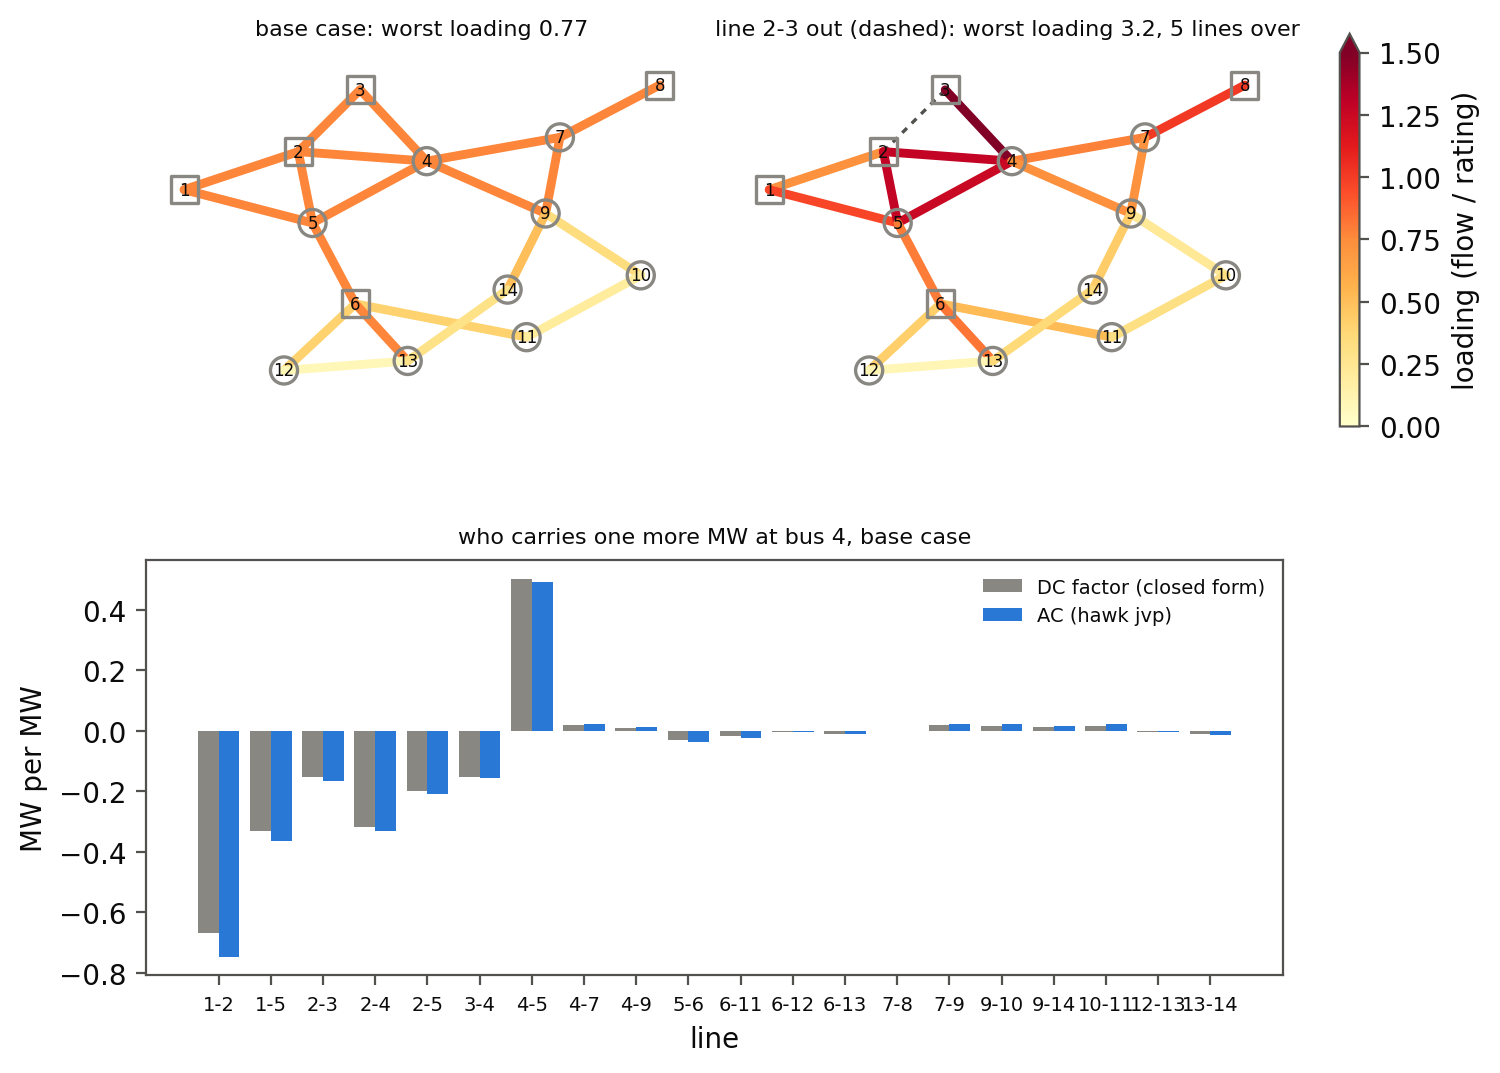
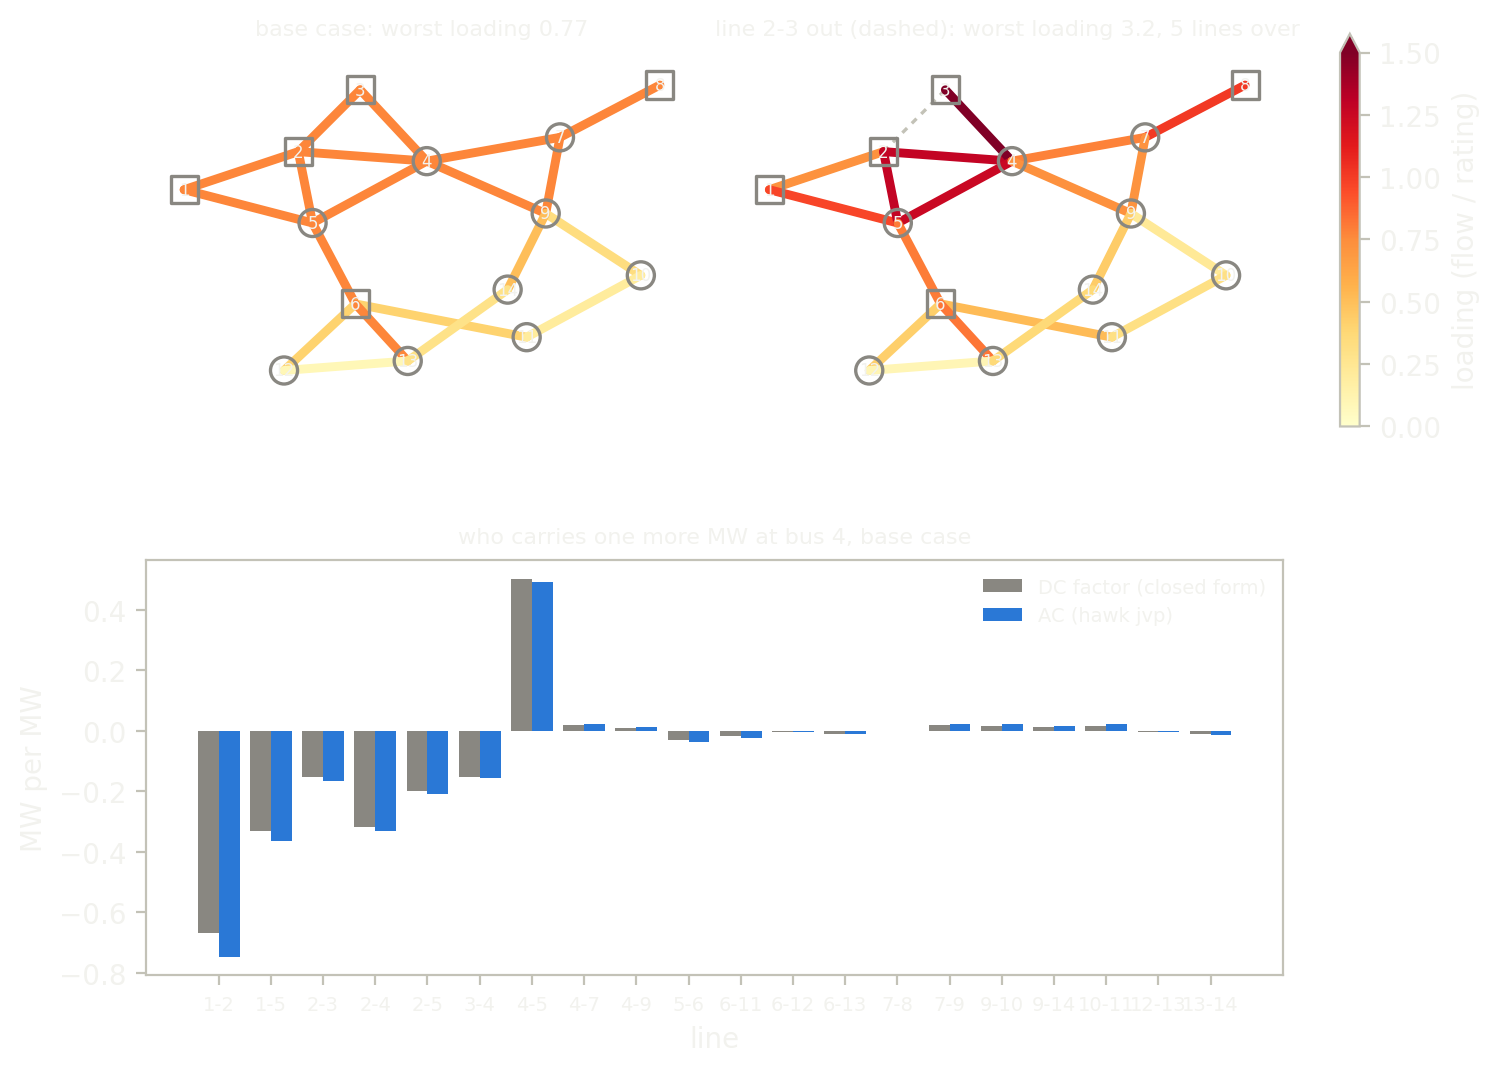

In [14]:
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

# fixed positions of the 14 buses (a Kamada-Kawai layout of the network, slack at the left)
XY = [(0.0, 3.8), (2.4, 4.6), (3.7, 5.9), (5.1, 4.4), (2.7, 3.1), (3.6, 1.4), (7.9, 4.9), (10.0, 6.0),
      (7.6, 3.3), (9.6, 2.0), (7.2, 0.7), (2.1, 0.0), (4.7, 0.2), (6.8, 1.7)]
norm = Normalize(0.0, 1.5)
cmap = plt.get_cmap("YlOrRd")
j23 = list(cases).index(LINE_NAME.index("2-3"))


def draw_grid(ax, j, title):
    for k, (f, t, *_rest) in enumerate(LINES):
        (x0, y0), (x1, y1) = XY[f - 1], XY[t - 1]
        if cases[j] == k:
            ax.plot([x0, x1], [y0, y1], ls=(0, (2, 2)), lw=1.2, color="#898781", zorder=1)
        else:
            ax.plot([x0, x1], [y0, y1], lw=3.2, color=cmap(norm(loading[j, k])), solid_capstyle="round", zorder=1)
    for i, (x, y) in enumerate(XY):
        ax.scatter([x], [y], s=95, marker="s" if HELD_V[i] is not None else "o", facecolor="none", edgecolor="#898781", linewidths=1.2, zorder=2)
        ax.text(x, y, str(i + 1), ha="center", va="center", fontsize=6, zorder=3)
    ax.set_xlim(-0.8, 10.8); ax.set_ylim(-0.8, 6.7); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(title, fontsize=8)


fig = plt.figure(figsize=(7.4, 5.6), constrained_layout=True)
grid_spec = fig.add_gridspec(2, 2, height_ratios=[1.35, 1.0])
base_ax, out_ax, bars = fig.add_subplot(grid_spec[0, 0]), fig.add_subplot(grid_spec[0, 1]), fig.add_subplot(grid_spec[1, :])
draw_grid(base_ax, 0, f"base case: worst loading {loading[0].max():.2f}")
draw_grid(out_ax, j23, f"line 2-3 out (dashed): worst loading {loading[j23].max():.1f}, {len(overloaded[j23])} lines over")
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=[base_ax, out_ax], location="right", shrink=0.7, extend="max", label="loading (flow / rating)")
at4 = list(buses).index(3)
bars.bar(np.arange(NL) - 0.2, closed[0, at4], 0.4, color="#898781", label="DC factor (closed form)")
bars.bar(np.arange(NL) + 0.2, dflow[0, at4], 0.4, color="#2a78d6", label="AC (hawk jvp)")
bars.set_xticks(np.arange(NL)); bars.set_xticklabels(LINE_NAME, fontsize=7)
bars.set_xlabel("line"); bars.set_ylabel("MW per MW"); bars.set_title("who carries one more MW at bus 4, base case", fontsize=8)
bars.legend(frameon=False, fontsize=7)
show(fig, f"Top: two drawings of the 14-bus grid. In the base case the lines are orange or paler, the most loaded at {loading[0].max():.2f} of its rating. With line 2-3 out (dashed) the line 3-4 beside bus 3 turns dark red, loaded to {loading[j23].max():.1f} times its rating, and {len(overloaded[j23])} lines are over their rating. Bottom: for each of the 20 lines, how its flow changes per extra megawatt injected at bus 4, DC closed form in grey beside AC in blue; line 1-2 changes by about {dflow[0, at4, 0]:.2f}, line 1-5 by {dflow[0, at4, 1]:.2f} and line 4-5 by {dflow[0, at4, 6]:+.2f}, and the two agree to about 0.1.")

## A bigger run, when a GPU is there

This cell runs only when a GPU is present; on a CPU runtime it prints that and does nothing. The same kernel and the same call run on device arrays. Every case at 400 load levels between 80 % and 110 % of the published load makes 8 400 lanes, each stopping on its own and each applying the switching rule. Every case but 1-2 must settle at every load level; outage 1-2 settles only up to a load below the published one, and the cell prints that range. The first 21 lanes are the sweep above and must agree with the host run to 1e-8 (devices round differently, so not bit for bit).

In [15]:
if gpu_available():
    levels = 400                                            # load levels per case
    big = NS * levels
    k = np.arange(big)
    outage_big = cases[k % NS]
    stress_big = np.where(k < NS, 1.0, np.linspace(0.8, 1.1, levels)[k // NS])
    got = grid.run(outage=xp.asarray(outage_big), kick=xp.asarray(np.full(big, -1, np.int32)), nudge=xp.asarray(np.zeros(big)),
                   stress=xp.asarray(stress_big), omega=OMEGA, tol=TOL)
    assert on_device(got["iterations"]), "the result is a device array: the kernel ran on the GPU"
    first = to_numpy(got["vre"]).T[:NS] + 1j * to_numpy(got["vim"]).T[:NS]
    assert np.nanmax(np.abs(first[ok] - volt[ok])) < 1e-8
    settled = to_numpy(got["settled"]) > 0.5
    other = outage_big != 0                                 # outage 1-2 converges only up to a load a little below the published one
    assert settled[other].all(), "every case but 1-2 settles"
    ok12 = settled[~other]
    on12 = stress_big[~other]
    print(f"{big} cases on the GPU: the first {NS} agree with the host run to 1e-8; every case but 1-2 settled within {MAXIT} iterations; "
          f"outage 1-2 settled for load x{on12[ok12].min():.2f} to x{on12[ok12].max():.2f} and not above")
else:
    print("no GPU here; the run stays at", NS, "cases")

8400 cases on the GPU: the first 21 agree with the host run to 1e-8; every case but 1-2 settled within 60 iterations; outage 1-2 settled for load x0.80 to x0.98 and not above


## What just happened

- `Network` named the outage, the nudge and the load level once; `power_flow` is one case's AC power flow by Newton's method, written in those names. The lane builds its 26 x 26 Jacobian with `m.mat`, solves it with `m.solve`, and enforces the machines' reactive limits with the one-way PV to PQ rule. `dc_flow` is the same for the DC model.
- Each lane took its own number of iterations and left the loop when its mismatch was small: 5 to 10 across the 20 cases that converge, the mismatch squaring each time.
- The base case matched the published IEEE solution. The 20 converging cases matched Newton's method in NumPy with the same switching rule, outage by outage, with the same machines switched, and the books closed at every bus. The loss of 1-2 has no solution in either, and a load ladder showed the two agree on which lanes converge.
- 13 of the 19 outages that converge overload at least one line against the assumed ratings; the loss of 2-3 is the worst by loading. Four outages push a machine to a reactive limit, and one outage is insecure.
- `jvp` gave the flow sensitivities through the iteration, its stop and its switches. They matched central differences and the sensitivity of the converged Newton solution, and the DC version matched the closed-form PTDF.

## Try this

Move a machine's limit, say bus 2's `Qmax` from 50 to 60 MVAr, and see which outages stop switching it. Or add a second nudge, a reactive one, and compare the voltage sensitivity of a load bus with its real-power sensitivity. Both are small edits to the kernel; the checks above stay as they are.

## Next

[Combustion](13_combustion) takes a gradient through a stop in a runaway reaction. [Reverse a whole rollout](05_tapes_and_events) covers gradients through many launches rather than one.